In [1]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
from collections import Counter
import pandas as pd
from sklearn.cluster import Birch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage1\dataset1_729×87.xlsx")
X = data.iloc[:, 3:]

feature_names = X.columns
X = StandardScaler().fit_transform(X)
min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)   
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
print(X.shape)

(729, 87)


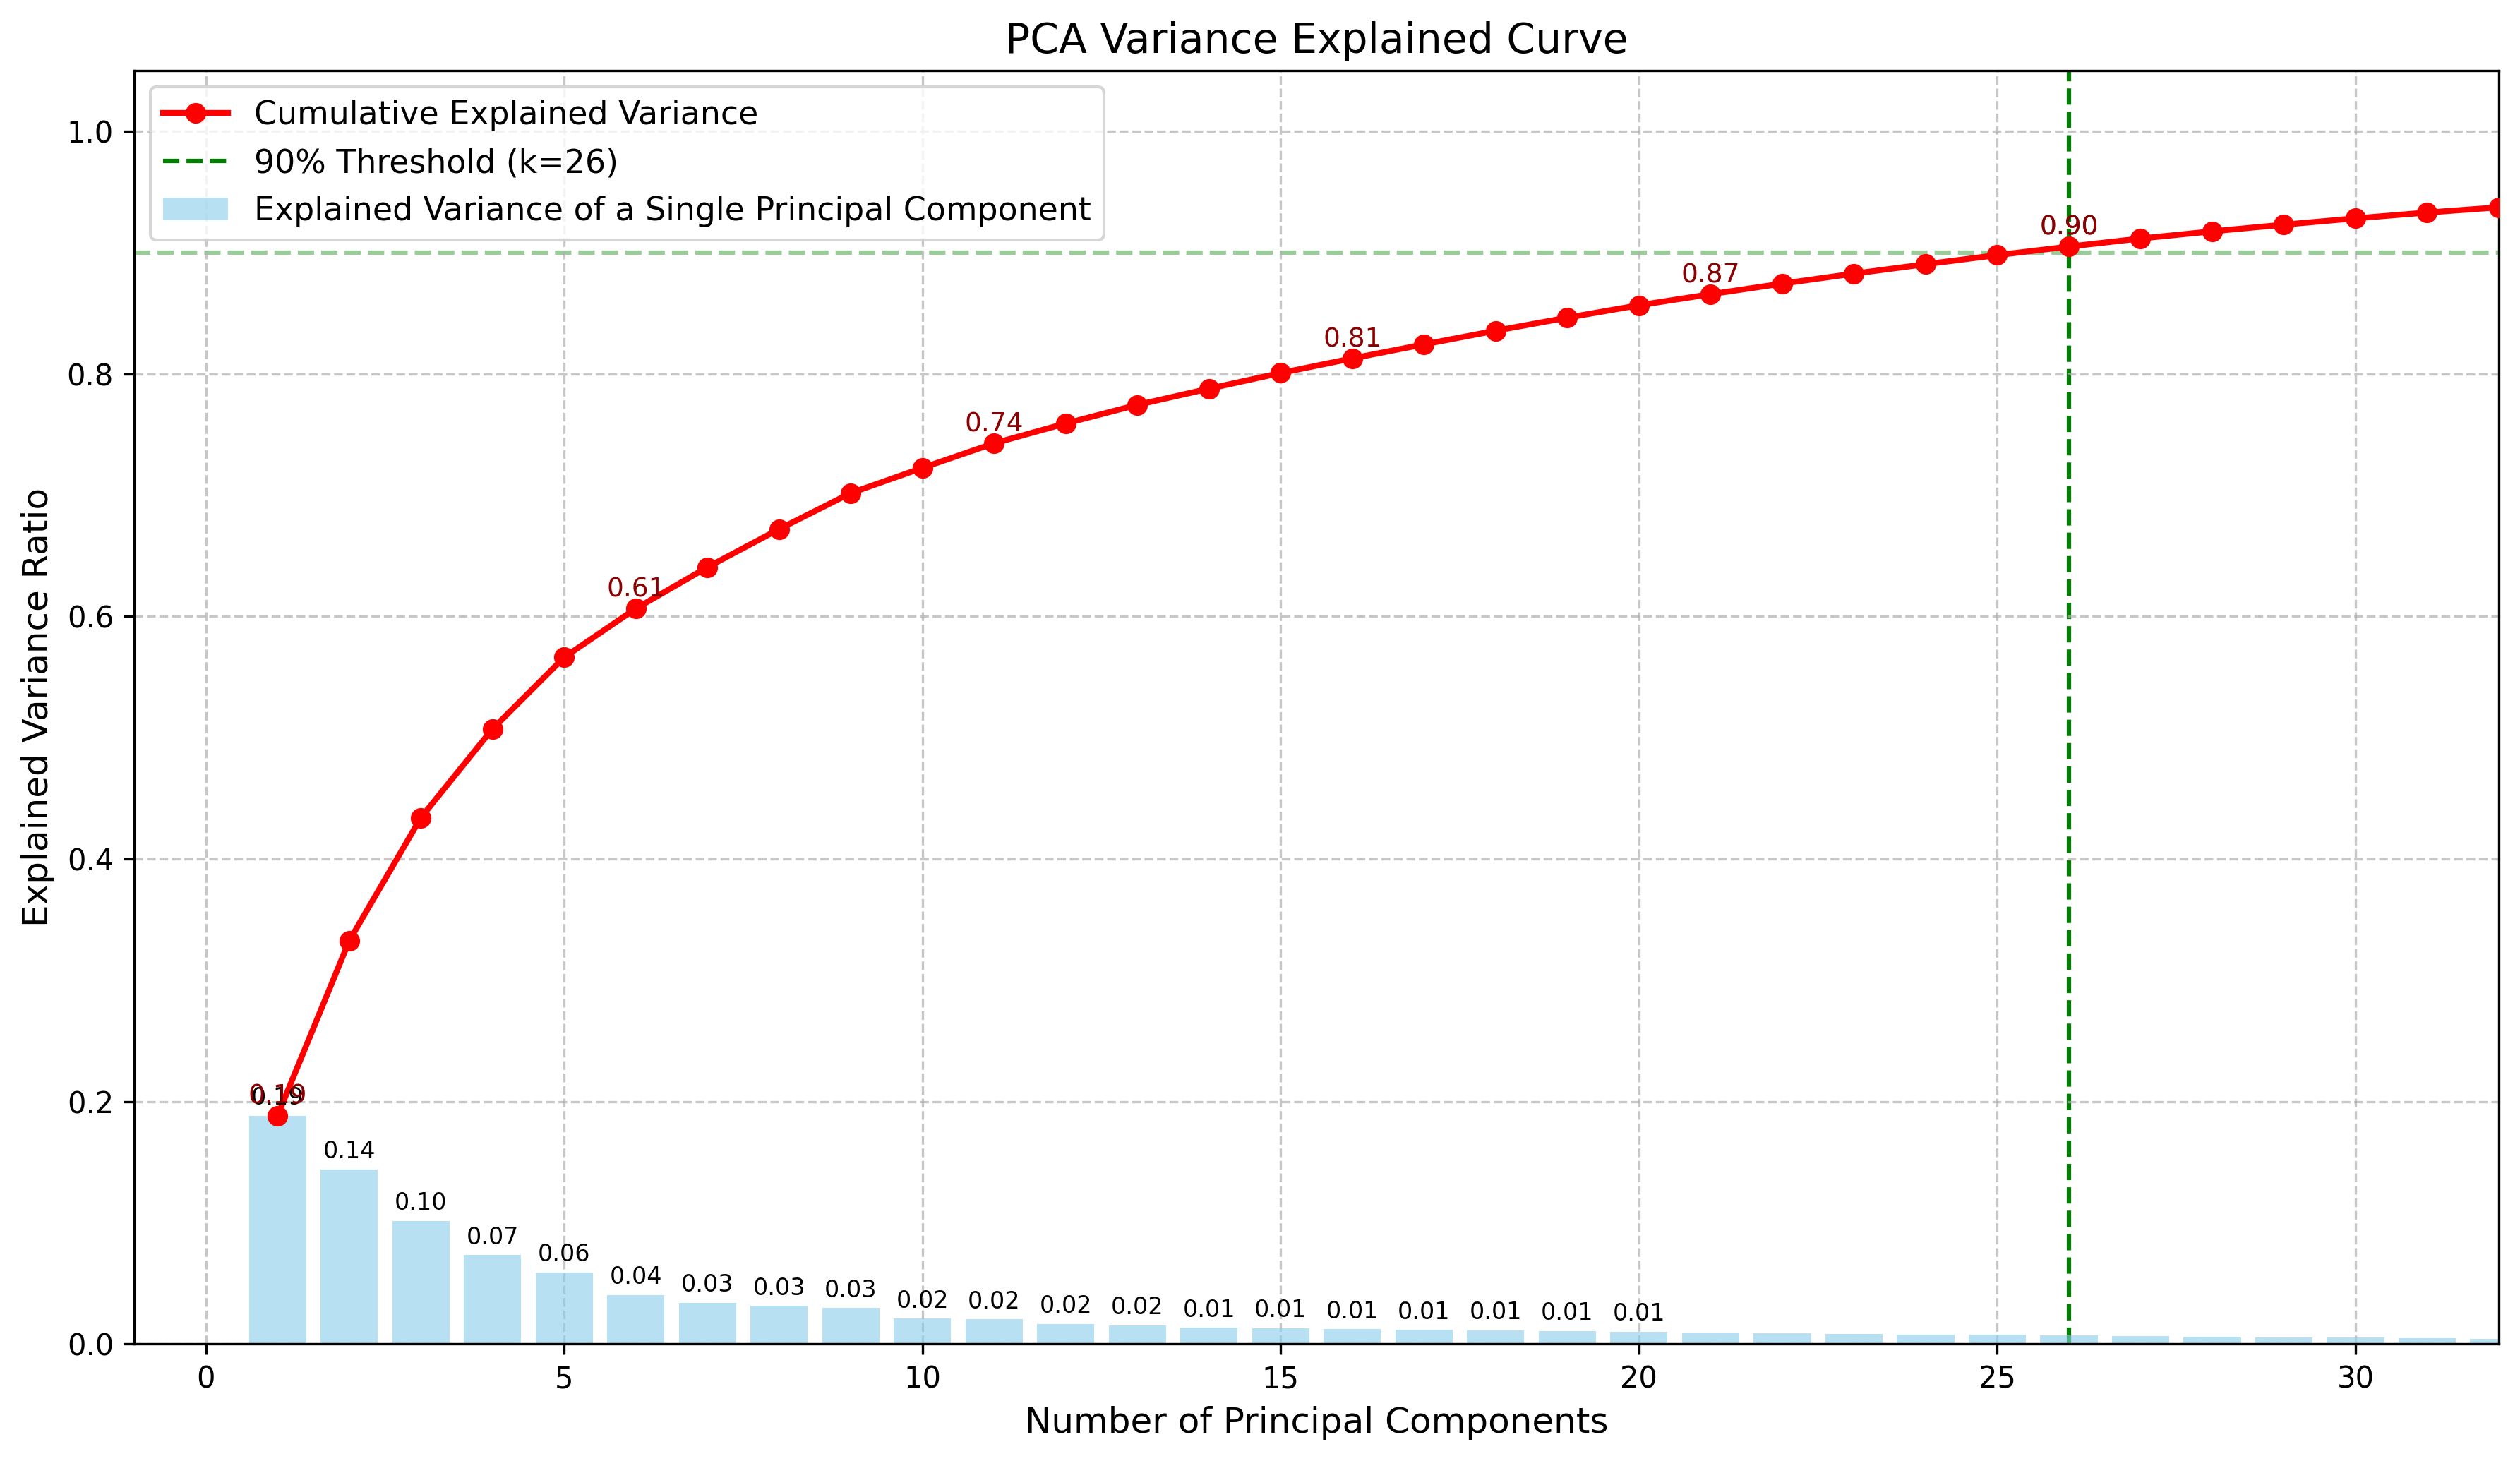

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ==========================================
# ==========================================

#try:
 #   df = pd.read_csv(data_path)
 #   X = df.values
    
 #   scaler = StandardScaler()
 #   X_scaled = scaler.fit_transform(X)
    
pca = PCA()
pca.fit(X)
    
explained_variance_ratio = pca.explained_variance_ratio_

#except FileNotFoundError:
 #   x_dummy = np.arange(1, 31)
 #   explained_variance_ratio = np.exp(-0.2 * x_dummy)
 #   explained_variance_ratio = explained_variance_ratio / np.sum(explained_variance_ratio)

# ==========================================
# ==========================================
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

cum_var = np.cumsum(explained_variance_ratio)
components_num = np.arange(1, len(explained_variance_ratio) + 1)

threshold = 0.90

k_threshold = np.argmax(cum_var >= threshold) + 1 
actual_threshold_val = cum_var[k_threshold - 1]


line = ax.plot(components_num, cum_var, color='red', marker='o', 
               linewidth=2, label='Cumulative Explained Variance', zorder=3)

vline = ax.axvline(x=k_threshold, color='green', linestyle='--', 
                   label=f'{int(threshold*100)}% Threshold (k={k_threshold})', zorder=1)
hline = ax.axhline(y=threshold, color='green', linestyle='--', alpha=0.4, zorder=1)

bars = ax.bar(components_num, explained_variance_ratio, color='skyblue', 
              alpha=0.6, label='Explained Variance of a Single Principal Component', zorder=2)


for i in range(min(21, len(components_num))):
    val = explained_variance_ratio[i]
    if val >= 0.01: 
        ax.text(components_num[i], val + 0.005, f'{val:.2f}', 
                ha='center', va='bottom', fontsize=8, color='black')


points_to_annotate = [1, 6, 11, 16, 21, k_threshold, 26] 
for p in points_to_annotate:
    if p <= len(components_num):
        val = cum_var[p-1]
        ax.text(components_num[p-1], val + 0.005, f'{val:.2f}', 
                ha='center', va='bottom', fontsize=9, color='darkred')


ax.set_xlabel('Number of Principal Components', fontsize=12)
ax.set_ylabel('Explained Variance Ratio', fontsize=12)
ax.set_title('PCA Variance Explained Curve', fontsize=14)

ax.set_xlim(-1, min(32, len(components_num) + 2))

ax.grid(True, linestyle='--', alpha=0.7)

ax.legend(loc='upper left', fontsize=11)

plt.tight_layout()

# ==========================================
# ==========================================
plt.savefig('PCA_Variance_Curve.pdf', format='pdf', dpi=300, bbox_inches='tight')

plt.show()